# Curve Curation Walkthrough: Winter Storm x Solar

This is the **start-here notebook** for understanding how the proposed `winter_storm_solar` curves are curated.
The companion `01_runtime_curve_walkthrough.ipynb` reads the same artifact and shows how a consumer evaluates it
and assembles a conditional loss.

```yaml
cell: winter_storm_solar
model: model v0.1 / docs r1 (proposed, not released, not in the artifact index)
grade: screening_engineering_proxy
pathway: snow_gravity_load (weight of snow, plus glaze ice, on the array)
```

The source of truth stays the cell package in `docs/cells/winter_storm_solar/proposed/`. This notebook is a
teaching and QA view, and it recomputes numbers from the committed artifact rather than copying them.

## What This Notebook Should Make Clear

By the end, you should be able to explain:

1. Why the curve is at **failure-unit grain** (racking and modules), not whole-plant grain.
2. Which evidence is allowed to support which part of the curve.
3. Why the x-axis is **event snow load / design snow load** for racking, and **kPa on the panels** for modules.
4. Why the curve form is a **lognormal ordered-damage-state** curve, not a logistic or a straight-line table.
5. How seven rack tests become a median, a spread, three scenarios and two damage states, giving about 21% at the design load.
6. Which parameters are evidence-backed and which are labelled placeholders.
7. What the selectors and conditioners do, how value is linked, and why capability is only "conditional".

In [1]:
from pathlib import Path
import json, math, sys
from math import erf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 120)

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("run this notebook from inside the damage_modeling repository")

ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))
from pathway_damage_curve_eval import PathwayEvaluationError, evaluate_ordered_damage_state_record
from winter_storm_solar_curve_eval import evaluate, assemble_loss, ground_frozen_load_kpa

CELL = ROOT / "docs/cells/winter_storm_solar/proposed"
ART_PATH = CELL / "winter_storm_solar__model_v0_1__docs_r1__curve_artifact.json"
artifact = json.loads(ART_PATH.read_text())
capability = artifact["capability_declaration"]
pathway = artifact["pathways"][0]
records = {r["failure_unit_id"]: r for r in pathway["curve_records"]}
STRUCT = records["WSS1_SUPPORT_STRUCTURE_COLLAPSE"]
MODULE = records["WSS1_MODULE_FIELD_BREAKAGE"]
OUT = Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
SCEN = ["lower_resistance", "central_screening", "upper_resistance"]
STYLE = {"lower_resistance": ("#85B7EB", "--", "weak"), "central_screening": ("#2a78d6", "-", "middle"),
         "upper_resistance": ("#185FA5", ":", "strong")}
phi = lambda z: 0.5 * (1 + erf(z / math.sqrt(2)))
print(artifact["cell_id"], "|", artifact["semantic_damage_model_version"], "|", artifact["documentation_revision"],
      "|", artifact["promotion_status"], "| canonical:", artifact["canonical_runtime_artifact"])

winter_storm_solar | model v0.1 | docs r1 | proposed | canonical: False


## 1. Scope First: Cell, Failure Unit, X-Axis, Y-Axis

Before fitting anything, the cell decides what the curve is allowed to mean.

```text
cell          = winter storm x ground-mount solar
pathway       = snow_gravity_load (snowpack + glaze weight); other winter mechanisms split off
failure units = racking/tracker structure (curve) · module field (curve) · others withheld
x-axis        = racking: event ground snow load / design ground snow load; modules: array snow load (kPa)
y-axis        = same-unit damage ratio = repair or replacement cost / that unit's replacement value
```

**Withheld does not mean zero.** It means the evidence is lacking.

In [2]:
units = pd.DataFrame([{k: f.get(k) for k in ("id", "subsystem", "treatment")} for f in artifact["failure_units"]])
display(units)
deferred = pd.DataFrame(artifact["deferred_pathways"])
display(deferred)

,id,subsystem,treatment
0,WSS1_SUPPORT_STRUCTURE_COLLAPSE,MOUNTING,primary_nonzero
1,WSS1_MODULE_FIELD_BREAKAGE,PV_ARRAY,primary_nonzero
2,WSS1_FOUNDATION,FOUNDATION,withheld
3,WSS1_POWER_CONVERSION_AND_ELECTRICAL,INVERTER_SYSTEM; ELECTRICAL_COLLECTION; SUBSTATION; GROUNDING_LIGHTNING,withheld
4,WSS1_SCADA_COMMUNICATIONS,SCADA,withheld
5,WSS1_CIVIL_INFRA,CIVIL_INFRA,withheld
6,WSS1_REPLACEMENT_SUPPORT,replacement support,exposure_modifier


,pathway_id,reason
0,ice_with_concurrent_wind,wind on iced or snow-loaded arrays is a combined case (WSS-S027); no evidence chain
1,ice_shedding_impact,falling or sliding ice/snow impact on neighbouring equipment; no evidence chain
2,snow_drift_and_sliding_impact,drift and sliding loads on equipment below arrays; no evidence chain


## 2. Evidence Map: What Each Source Class Is Allowed To Do

A source can be strong for one purpose and useless for another. Each source in the register has a **role** and
a stated **permitted / prohibited inference**. Nobody has published a ready-made snow damage curve for solar, so
the curve is assembled from source classes that each support only one link in the chain.

In [3]:
src = pd.read_csv(CELL / "SOURCE_REGISTER_winter_storm_solar__model_v0_1__docs_r1.csv")
roles = (src.groupby("source_role").agg(sources=("source_id", lambda s: ", ".join(s)), count=("source_id", "size"))
            .sort_values("count", ascending=False))
display(roles)

evidence_classes = pd.DataFrame([
    {"evidence class": "Physics / standards (NOAA ice model, ASCE 7-22 commentary)", "allowed to support": "snow and glaze to load; axis meaning", "not allowed": "any damage number"},
    {"evidence class": "Full-scale rack failure tests (NEDO 2019, JSME 2019)", "allowed to support": "racking capacity median and spread vs design", "not allowed": "US design mapping; tracker capacity"},
    {"evidence class": "Regulator accident records (NITE 2023, 2025)", "allowed to support": "damage levels once snow exceeded design (37%, 80%, total)", "not allowed": "event/design ratios; rates per plant"},
    {"evidence class": "Module lab tests (CFV Labs, Kiwa PVEL)", "allowed to support": "module breaking load range 1.8-2.8 kPa", "not allowed": "non-uniform snow capacity of a specific product"},
    {"evidence class": "Field forensics / press (Andorra 2026, Turkey, Japan)", "allowed to support": "failure modes; design deficiency dominates", "not allowed": "numeric ratios"},
    {"evidence class": "Manufacturer specs (NOV, Array, GameChange)", "allowed to support": "tracker snow ratings are project choices; stow exists", "not allowed": "stow efficacy credit"},
])
display(evidence_classes)

,sources,count
source_role,,
mechanism_only,"WSS-S003, WSS-S004, WSS-S005, WSS-S006, WSS-S009, WSS-S014, WSS-S016, WSS-S017, WSS-S024, WSS-S027, WSS-S029",11
axis_bridge,"WSS-S001, WSS-S002, WSS-S015, WSS-S019, WSS-S025, WSS-S031",6
curve_fit_shape,"WSS-S011, WSS-S022, WSS-S023",3
case_study_severity,"WSS-S013, WSS-S028",2
claims_or_field_calibration,"WSS-S021, WSS-S030",2
conditioner_adjustment,"WSS-S007, WSS-S018",2
selector_archetype,"WSS-S012, WSS-S026",2
boundary_or_cap,WSS-S010,1
exposure_or_value,WSS-S032,1


,evidence class,allowed to support,not allowed
0,"Physics / standards (NOAA ice model, ASCE 7-22 commentary)",snow and glaze to load; axis meaning,any damage number
1,"Full-scale rack failure tests (NEDO 2019, JSME 2019)",racking capacity median and spread vs design,US design mapping; tracker capacity
2,"Regulator accident records (NITE 2023, 2025)","damage levels once snow exceeded design (37%, 80%, total)",event/design ratios; rates per plant
3,"Module lab tests (CFV Labs, Kiwa PVEL)",module breaking load range 1.8-2.8 kPa,non-uniform snow capacity of a specific product
4,"Field forensics / press (Andorra 2026, Turkey, Japan)",failure modes; design deficiency dominates,numeric ratios
5,"Manufacturer specs (NOV, Array, GameChange)",tracker snow ratings are project choices; stow exists,stow efficacy credit


## 3. X-Axis Decision: From Snow To Load, Then Event / Design

The hazard grid supplies **snow water equivalent (SWE)**, the depth of water the snow would melt to. That
converts to weight with no guessing, because 1 mm of water on 1 m² weighs 1 kg:

```text
ground load (kPa) = SWE (mm) x 0.00980665  +  glaze: pi x 0.9 x radial ice (mm) x 0.00980665
r (racking)       = ground load / ASCE 7-22 design ground snow load      (or array load / rated load, per asset)
q (modules)       = Cs x 0.7 x Ce x Ct x ground load                     (Ce 0.9, Ct 1.2, Cs 1.0 = no slope credit)
```

Rejected axes:
- **Raw kPa for racking.** It misprices north vs south, because the same snow hits under-built southern
  arrays and over-built northern ones.
- **Snow depth.** Converting depth needs a density guess that varies 3-5x.

In [4]:
examples = []
for swe, ice, site, design in [(60, 0, "north Texas", 0.48), (150, 0, "north Texas", 0.48), (150, 0, "Missouri", 0.96),
                               (150, 0, "Minnesota", 2.39), (120, 12, "Missouri", 0.96)]:
    g = ground_frozen_load_kpa(swe, ice)
    examples.append({"SWE_mm": swe, "glaze_ice_mm": ice, "ground_load_kPa": round(g, 3), "site (illustrative)": site,
                     "design_kPa": design, "r = event / design": round(g / design, 2)})
display(pd.DataFrame(examples))
print("Design loads here are illustrative magnitudes, not ASCE 7-22 lookups.")

,SWE_mm,glaze_ice_mm,ground_load_kPa,site (illustrative),design_kPa,r = event / design
0,60,0,0.588,north Texas,0.48,1.23
1,150,0,1.471,north Texas,0.48,3.06
2,150,0,1.471,Missouri,0.96,1.53
3,150,0,1.471,Minnesota,2.39,0.62
4,120,12,1.510,Missouri,0.96,1.57


Design loads here are illustrative magnitudes, not ASCE 7-22 lookups.


## 4. Curve-Form Choice: Why Lognormal Ordered Damage States?

The chosen form is the repository's `ordered_damage_state_lognormal`. Each damage state k has a median capacity
m_k, all share one spread beta, and the expected damage ratio is:

```text
P_k(x) = Phi( ln(x / m_k) / beta )                        share of racks past state k at demand x
DR(x)  = sum_k cost_k x ( P_k(x) - P_{k+1}(x) )           expected same-unit damage ratio
```

Why this form fits the evidence:
- the evidence is **capacity measurements** (racks loaded to failure). A lognormal is the standard fragility
  form for "share of structures failed by this load", and it keeps capacity positive;
- **damage states** let partial and extensive collapse carry different costs, which matches the accident records;
- **capacity scenarios** carry the unresolved design-load mapping without pretending it's a probability;
- the same form is used by `strong_wind_solar` v2.0 (proposed), so consumers already know how to read it.

In [5]:
alternatives = pd.DataFrame([
    {"form": "Logistic on raw kPa (legacy style)", "decision": "Rejected", "reason": "ignores design load; no tie to measured capacities"},
    {"form": "Straight lines between points", "decision": "Rejected", "reason": "only 7 tests; jagged and silent outside the tested range"},
    {"form": "Single whole-plant curve", "decision": "Rejected", "reason": "racking and modules fail differently and have different values"},
    {"form": "Lognormal ordered damage states + scenarios", "decision": "Selected", "reason": "fits capacity data, damage levels and mapping uncertainty"},
])
display(alternatives)

,form,decision,reason
0,Logistic on raw kPa (legacy style),Rejected,ignores design load; no tie to measured capacities
1,Straight lines between points,Rejected,only 7 tests; jagged and silent outside the tested range
2,Single whole-plant curve,Rejected,racking and modules fail differently and have different values
3,Lognormal ordered damage states + scenarios,Selected,"fits capacity data, damage levels and mapping uncertainty"


## 5. Fitting: From Seven Tests To Medians, Scenarios And Damage States

### 5a. The measured capacities

Seven full-scale ground-mount racks were tested to failure in Japan:
- six commercial racks in a pressure chamber (NEDO 2019 guideline, technical annex D, Table D5; `WSS-S022`);
- one rack loaded with sandbags (Maeda et al., Trans. JSME 2019; `WSS-S023`).

Both sets of numbers were checked in the original documents.

In [6]:
tests = pd.DataFrame([
    ("WSS-S022", "i steel 4x2", 1294, 4250), ("WSS-S022", "ii steel 4x4", 1294, 1750),
    ("WSS-S022", "iii aluminium 4x5", 1036, 1000), ("WSS-S022", "iv aluminium+steel 4x5", 1036, 2250),
    ("WSS-S022", "v aluminium+steel 4x6", 688, 2000), ("WSS-S022", "vi steel scaffold pipe 4x4", 1036, 1250),
    ("WSS-S023", "JSME thin-wall steel truss", 1980, 5038),
], columns=["source", "specimen", "design_Pa", "failure_Pa"])
tests["failure_over_design"] = (tests.failure_Pa / tests.design_Pa).round(2)
display(tests.sort_values("failure_over_design"))

logs = np.log(tests.failure_over_design)
median_test = float(np.exp(logs.mean()))
beta_test = float(logs.std(ddof=1))
print(f"typical breaking point (log-mean) = {median_test:.2f} x design")
print(f"spread (log standard deviation)   = {beta_test:.2f}")
print(f"artifact beta_ln                  = {STRUCT['parameters']['beta_ln']}")

,source,specimen,design_Pa,failure_Pa,failure_over_design
2,WSS-S022,iii aluminium 4x5,1036,1000,0.97
5,WSS-S022,vi steel scaffold pipe 4x4,1036,1250,1.21
1,WSS-S022,ii steel 4x4,1294,1750,1.35
3,WSS-S022,iv aluminium+steel 4x5,1036,2250,2.17
6,WSS-S023,JSME thin-wall steel truss,1980,5038,2.54
4,WSS-S022,v aluminium+steel 4x6,688,2000,2.91
0,WSS-S022,i steel 4x2,1294,4250,3.28


typical breaking point (log-mean) = 1.88 x design
spread (log standard deviation)   = 0.47
artifact beta_ln                  = 0.47


### 5b. Three scenarios: converting Japanese design loads to US design loads

The tests measure against the **manufacturer's (Japanese) design load**. Our axis uses the **ASCE 7-22**
strength-level design load. The conversion isn't published, so three unweighted scenarios are carried. They are
**bounds, not percentiles**.

In [7]:
mapping = {"lower_resistance": (0.56, "test design = old 50-year nominal load"),
           "central_screening": (0.70, "US racking designed by allowable stress to 0.7 x design load"),
           "upper_resistance": (1.00, "test design taken as equal to ASCE 7-22 load")}
rows = []
for sc in STRUCT["parameters"]["capacity_scenarios"]:
    f, why = mapping[sc["scenario_id"]]
    rows.append({"scenario": sc["scenario_id"], "factor": f, "reason": why, "1.88 x factor": round(1.88 * f, 3),
                 "artifact DS1 median": sc["state_medians"][0], "artifact DS2 median": sc["state_medians"][1]})
display(pd.DataFrame(rows))

,scenario,factor,reason,1.88 x factor,artifact DS1 median,artifact DS2 median
0,lower_resistance,0.56,test design = old 50-year nominal load,1.053,1.05,1.260
1,central_screening,0.70,US racking designed by allowable stress to 0.7 x design load,1.316,1.32,1.584
2,upper_resistance,1.00,test design taken as equal to ASCE 7-22 load,1.880,1.88,2.256


### 5c. Damage states from accident records

Japanese regulator records (NITE 2025, `WSS-S030`) report snow events that exceeded design and damaged about
**37%**, about **80%**, and **100%** of the array:

| State | Cost (share of racking value) | Basis |
|---|---|---|
| partial collapse (DS1) | 0.40 | the ~37% case |
| extensive collapse (DS2) | 1.00 | the ~80% and total cases |

DS2 median = 1.2 x DS1 median is a labelled assumption (T4), reflecting the JSME rack's sudden collapse right
after its first post buckled.

In [8]:
display(pd.DataFrame([{k: s[k] for k in ("state_id", "cost_ratio", "tier")} for s in STRUCT["parameters"]["damage_states"]]))

,state_id,cost_ratio,tier
0,STRUCT_DS0_NO_STRUCTURAL_DAMAGE,0.0,T4_placeholder_or_expert_judgment
1,STRUCT_DS1_PARTIAL_ARRAY_COLLAPSE,0.4,T3_engineering_proxy_or_adjacent_empirical
2,STRUCT_DS2_EXTENSIVE_COLLAPSE,1.0,T3_engineering_proxy_or_adjacent_empirical


### 5d. Worked value: why "about 21% at the design load"

Middle scenario, `r = 1.0` (storm snow exactly equals what the racking was built for).

In [9]:
r, b = 1.0, STRUCT["parameters"]["beta_ln"]
m1, m2 = STRUCT["parameters"]["capacity_scenarios"][1]["state_medians"]
p_partial = phi(math.log(r / m1) / b)
p_extensive = phi(math.log(r / m2) / b)
dr = p_extensive * 1.0 + (p_partial - p_extensive) * 0.40
print(f"past partial collapse   = {p_partial:.3f}")
print(f"past extensive collapse = {p_extensive:.3f}")
print(f"only partial            = {p_partial - p_extensive:.3f}")
print(f"expected damage         = {p_extensive:.3f} x 1.00 + {p_partial - p_extensive:.3f} x 0.40 = {dr:.4f}")
via_evaluator = evaluate_ordered_damage_state_record(STRUCT, r)["central_screening"]["damage_ratio"]
print(f"reference evaluator     = {via_evaluator:.4f}  (match: {abs(dr - via_evaluator) < 1e-12})")

past partial collapse   = 0.277
past extensive collapse = 0.164
only partial            = 0.113
expected damage         = 0.164 x 1.00 + 0.113 x 0.40 = 0.2093
reference evaluator     = 0.2093  (match: True)


### 5e. Module curve parameters

- Lab test-to-failure data show modern large panels break at about **1.8-2.8 kPa** (CFV Labs, Kiwa PVEL).
- Snow presses hardest on the lower edge (IEC 62938; AIST field measurements), so capacity is multiplied by **0.85** (T4).
- That gives medians of **1.53 / 1.96 / 2.38 kPa**, with spread beta = 0.25 (T4).

In [10]:
display(pd.DataFrame([{"scenario": s["scenario_id"], "median_kPa": round(s["state_medians"][0], 3),
                       "before knock-down": round(s["state_medians"][0] / 0.85, 2)} for s in MODULE["parameters"]["capacity_scenarios"]]))
print("module beta_ln =", MODULE["parameters"]["beta_ln"])

,scenario,median_kPa,before knock-down
0,lower_resistance,1.530,1.8
1,central_screening,1.955,2.3
2,upper_resistance,2.380,2.8


module beta_ln = 0.25


## 6. Visual QA: Do The Fitted Curves Match The Evidence?

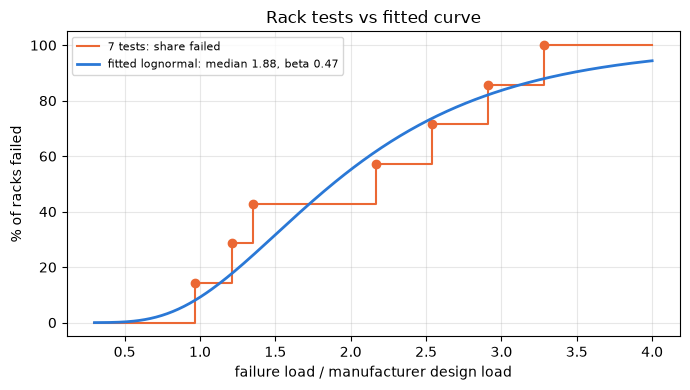

In [11]:
x = np.linspace(0.3, 4, 300)
fig, ax = plt.subplots(figsize=(7, 4))
srt = np.sort(tests.failure_over_design.values)
ax.step(np.r_[0.3, srt, 4], np.r_[0, np.arange(1, 8) / 7, 1] * 100, where="post", color="#eb6834", label="7 tests: share failed")
ax.plot(srt, np.arange(1, 8) / 7 * 100, "o", color="#eb6834")
ax.plot(x, [100 * phi(math.log(v / median_test) / beta_test) for v in x], color="#2a78d6", lw=2,
        label=f"fitted lognormal: median {median_test:.2f}, beta {beta_test:.2f}")
ax.set(xlabel="failure load / manufacturer design load", ylabel="% of racks failed", title="Rack tests vs fitted curve")
ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "00_rack_tests_vs_fit.png", dpi=150); plt.show()

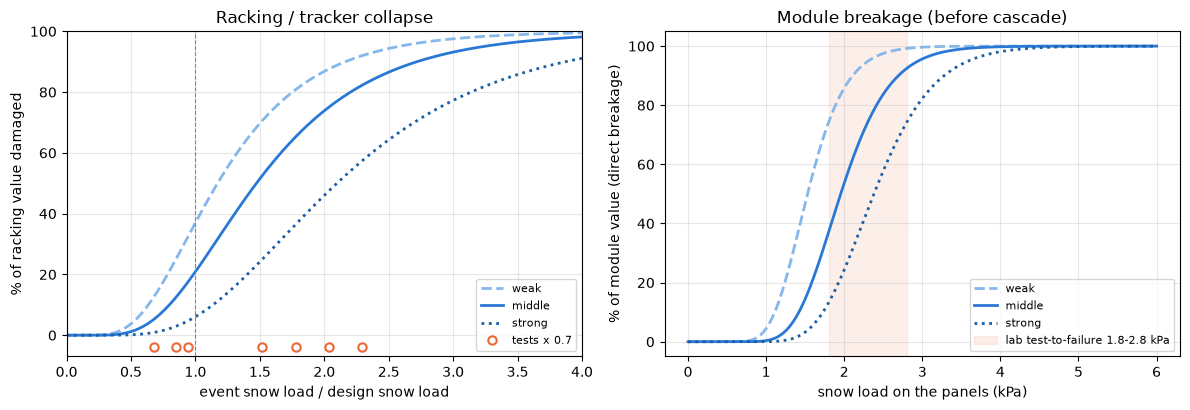

sanity: 3 of 7 tested racks fail below the US design load under the middle mapping; the middle curve puts 28% of racks past collapse onset at r = 1


,r,weak,middle,strong
0,0.5,3.8,1.2,0.1
1,0.8,21.3,10.1,2.2
2,1.0,37.0,20.9,6.1
3,1.2,52.0,33.4,12.2
4,1.5,69.7,51.5,24.2
5,2.0,86.8,73.9,46.0
6,3.0,97.5,93.2,77.3


In [12]:
mapped = tests.failure_over_design * 0.70
xs = np.linspace(0, 4, 201)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for sid in SCEN:
    c, ls, lab = STYLE[sid]
    a1.plot(xs, [100 * evaluate_ordered_damage_state_record(STRUCT, v)[sid]["damage_ratio"] for v in xs], color=c, ls=ls, lw=2, label=lab)
a1.plot(mapped, [-4] * 7, "o", mfc="white", mec="#eb6834", mew=1.5, clip_on=False, label="tests x 0.7")
a1.axvline(1, color="#898781", lw=.8, ls="--")
a1.set(xlim=(0, 4), ylim=(-7, 100), xlabel="event snow load / design snow load", ylabel="% of racking value damaged",
       title="Racking / tracker collapse")
a1.grid(alpha=.3); a1.legend(fontsize=8, loc="lower right")
qs = np.linspace(0, 6, 201)
for sid in SCEN:
    c, ls, lab = STYLE[sid]
    a2.plot(qs, [100 * evaluate_ordered_damage_state_record(MODULE, v)[sid]["damage_ratio"] for v in qs], color=c, ls=ls, lw=2, label=lab)
a2.axvspan(1.8, 2.8, color="#eb6834", alpha=.1, label="lab test-to-failure 1.8-2.8 kPa")
a2.set(xlabel="snow load on the panels (kPa)", ylabel="% of module value (direct breakage)", title="Module breakage (before cascade)")
a2.grid(alpha=.3); a2.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(OUT / "00_curves.png", dpi=150); plt.show()

print(f"sanity: {int((mapped < 1).sum())} of 7 tested racks fail below the US design load under the middle mapping;"
      f" the middle curve puts {100 * p_partial:.0f}% of racks past collapse onset at r = 1")
display(pd.DataFrame([{"r": v, **{STYLE[s][2]: round(100 * evaluate_ordered_damage_state_record(STRUCT, v)[s]["damage_ratio"], 1) for s in SCEN}}
                      for v in (0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 3.0)]))

## 7. Parameter Tiers: Evidence-Backed vs Placeholder

Every parameter carries an evidence tier:
- **T1:** claims or field records.
- **T2:** standards, lab tests or physics.
- **T3:** engineering proxy.
- **T4:** placeholder or expert judgement.

The measured spread and the physics are T2. The scenario mapping, the collapse spacing, the knock-down and
salvage are T4, and labelled as such.

In [13]:
tiers = pd.read_csv(CELL / "PARAMETER_TIER_TABLE_winter_storm_solar__model_v0_1__docs_r1.csv")
display(tiers[["parameter", "value", "tier", "source_ids"]])
display(tiers.tier.value_counts().rename("count"))

,parameter,value,tier,source_ids
0,pathway_id,snow_gravity_load; no default,T4_placeholder_or_expert_judgment,WSS-S019
1,swe_to_kpa,0.00980665 kPa per mm SWE,T2_public_lab_standard_or_physics,WSS-S031
2,glaze_kpa_per_mm_radial,pi x 0.9 x 0.00980665 = 0.027726,T2_public_lab_standard_or_physics,WSS-S031
3,flat_roof_factor,0.7,T2_public_lab_standard_or_physics,WSS-S002
4,exposure_factor_ce,0.9,T3_engineering_proxy_or_adjacent_empirical,WSS-S025
5,thermal_factor_ct,1.2,T3_engineering_proxy_or_adjacent_empirical,WSS-S025
6,default_slope_factor_cs,1.0,T4_placeholder_or_expert_judgment,WSS-S006;WSS-S025
7,structure_beta_ln,0.47,T2_public_lab_standard_or_physics,WSS-S022;WSS-S023
8,structure_DS1_median_lower,1.05,T4_placeholder_or_expert_judgment,WSS-S022;WSS-S023;WSS-S019
9,structure_DS1_median_central,1.32,T4_placeholder_or_expert_judgment,WSS-S022;WSS-S023;WSS-S002


tier
T4_placeholder_or_expert_judgment             14
T3_engineering_proxy_or_adjacent_empirical     5
T2_public_lab_standard_or_physics              4
Name: count, dtype: int64

## 8. Selectors And Conditioners: Fixed Facts vs Event-Time State

- **Selectors** are fixed facts about the asset: architecture, and the racking design basis (code-assumed for the
  screening grid, project-rated per asset).
- **Conditioners** are event-time state: ice basis, slope factor, snow stow, snow removal.

No control gets blanket credit: snow stow and snow removal are **captured with no numeric credit**, because no
efficacy evidence was found.

In [14]:
display(pd.DataFrame([{"field": s["field"], "required": s.get("required", s.get("required_when")), "numeric_effect": s["numeric_effect"]}
                      for s in pathway["selector_logic"]]))
display(pd.DataFrame([{"field": c["field"], "required": c.get("required"), "numeric_effect": c["numeric_effect"]}
                      for c in pathway["conditioner_logic"]]))

,field,required,numeric_effect
0,array_architecture,True,none in v0.1; single_axis_tracker adds TRACKER_TRANSFER_FROM_FIXED_RACK_TESTS
1,racking_design_basis,True,selects the structure-ratio denominator
2,design_ground_snow_load_kpa,racking_design_basis=site_code_assumed,structure ratio denominator (ASCE 7-22 strength-level pg)
3,racking_rated_array_snow_load_kpa,racking_design_basis=project_rated,structure ratio denominator on the array-load basis
4,design_risk_category,capture_or_unknown,none; records which ASCE 7-22 map supplied the design load


,field,required,numeric_effect
0,ice_component_basis,True,not_in_hazard_product evaluates snow only and flags ICE_COMPONENT_NOT_SUPPLIED_LOWER_BOUND
1,slope_factor_cs,False,module axis only; a value below 1 is flagged SLOPE_FACTOR_CREDIT_SUPPLIED_UNCALIBRATED
2,snow_stow_state,capture_or_unknown,none; no stow credit
3,leading_edge_clearance_m,capture_or_unknown,none; capture only
4,snow_removal_performed,capture_or_unknown,none; no removal credit


## 9. Value Linkage: Curves Do Not Own The Whole Plant Value

Each curve acts on **its own unit's value**: modules $291.21/kWdc, racking $109.99/kWdc (2024 USD reference).
The support pool (field labour, site management: $189.59/kWdc) is allocated **once** after direct damage.
Foundations, electrical, SCADA and civil are withheld. The crosswalk reconciles to $877.80/kWdc physical and
$1,120/kWdc installed.

In [15]:
val = pd.read_csv(CELL / "VALUE_CROSSWALK_winter_storm_solar__model_v0_1__docs_r1.csv")
display(val[["row_or_bucket_label", "value", "failure_unit_id", "role_in_loss"]])
print("physical total =", round(val.loc[val.financial_class != "excluded_soft_sunk", "value"].sum(), 2),
      "| installed total =", round(val.value.sum(), 2))

,row_or_bucket_label,value,failure_unit_id,role_in_loss
0,Module hardware + module-level,291.214851,WSS1_MODULE_FIELD_BREAKAGE,direct_vulnerable_value
1,SBOS tracker/racking hardware,109.989726,WSS1_SUPPORT_STRUCTURE_COLLAPSE,direct_vulnerable_value
2,SBOS driven piers + EBOS pad,31.124487,WSS1_FOUNDATION,withheld
3,Central inverter hardware,32.306366,WSS1_POWER_CONVERSION_AND_ELECTRICAL,withheld
4,EBOS combiner boxes,6.826250,WSS1_POWER_CONVERSION_AND_ELECTRICAL,withheld
5,EBOS conductors,69.320112,WSS1_POWER_CONVERSION_AND_ELECTRICAL,withheld
6,EBOS transformer/switches/breakers/substation,106.504664,WSS1_POWER_CONVERSION_AND_ELECTRICAL,withheld
7,EBOS grounding / lightning,8.385000,WSS1_POWER_CONVERSION_AND_ELECTRICAL,withheld
8,EBOS system monitor,1.310000,WSS1_SCADA_COMMUNICATIONS,withheld
9,Grid network upgrade,38.253731,OUTSIDE_PHYSICAL_CELL,excluded


physical total = 877.8 | installed total = 1120.0


## 10. Capability Gate

The cell declares what it can and cannot emit. Damage ratios are **conditional**: available only with a
declared pathway, architecture, design basis and SWE payload. Annual metrics (EAL, PML) belong to the Hazard
consumer, and promotion is blocked until review.

In [16]:
pc = capability["pathway_capabilities"][0]
display(pd.DataFrame([{"item": k, "value": pc[k]} for k in ("failure_unit_scalar_dr", "scenario_loss_given_value_basis", "curve_intrinsic_spread")]))
display(pd.DataFrame({"limitation flags": pc["limitation_flags"]}))
display(pd.DataFrame({"required before canonical use": capability["promotion_gate"]["required_before_canonical_use"]}))

,item,value
0,failure_unit_scalar_dr,conditional
1,scenario_loss_given_value_basis,conditional
2,curve_intrinsic_spread,nonprobabilistic_epistemic_envelope


,limitation flags
0,SCREENING_ENGINEERING_PROXY
1,NONPROBABILISTIC_EPISTEMIC_ENVELOPE
2,CAPACITY_FROM_SEVEN_JAPANESE_FIXED_RACK_TESTS
3,JAPANESE_TO_ASCE_DESIGN_LOAD_MAPPING_UNRESOLVED
4,TRACKER_TRANSFER_FROM_FIXED_RACK_TESTS
5,SNOW_STOW_AND_SNOW_REMOVAL_NO_CREDIT
6,MODULE_CAPACITY_T3_LOWER_EDGE_KNOCKDOWN_T4
7,MODULE_SALVAGE_T4_ASSUMPTION
8,NO_US_FIELD_OR_CLAIMS_CALIBRATION
9,FULL_PLANT_PHYSICAL_LOSS_INCOMPLETE


,required before canonical use
0,"independent engineering review of axis, bridge, scenarios and cascade"
1,ASCE 7-22 Ch.7 and the ASCE 2025 ground-mount snow guidance read and reconciled
2,tracker-specific snow capacity evidence or an explicit tracker transfer review
3,"US field, forensic or claims evidence sufficient to review the T4 mapping"
4,Hazard dual-read and rejection-path tests
5,explicit maintainer promotion decision and atomic registry/index/changelog update


## 11. Open Seams And Upgrade Triggers

| Seam | What would close it |
|---|---|
| Japanese to ASCE design-load mapping (the scenario spread) | US full-scale rack/tracker tests against ASCE 7-22 loads; ASCE's 2025 ground-mount snow guidance (paywalled) |
| Trackers vs fixed racks | tracker-specific snow tests (all seven tests are fixed-tilt racks) |
| Damage-state costs (3 cases) | more accident cases with damaged share and snow load |
| Panel knock-down, spread, salvage | IEC 62938 load table; snow-specific module tests; salvage records |
| No US calibration | US forensic or insurance claims data |

## 12. Reviewer Checklist

| Check | Where |
|---|---|
| Pathway split and exclusions (BI, cold, flood, wind) are explicit | Section 1; derivation dossier §1 |
| Every source has a role and permitted/prohibited inference | Section 2; source register |
| Axis uses SWE and design load; depth rejected | Section 3; metadata spec |
| Curve form justified against alternatives | Section 4 |
| Medians and spread reproduce from the seven tests | Section 5a; Section 6 |
| Scenarios labelled as bounds, not percentiles | Section 5b; capability flags |
| Worked value reproduces the evaluator (about 21% at r = 1) | Section 5d |
| T4 placeholders are visible | Section 7 |
| No stow or removal credit | Section 8 |
| Value applied per unit; support once; withheld is not zero | Section 9 |
| Capability conditional; promotion blocked | Section 10 |